In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import ImageProcessing as ip
from sklearn.neighbors import KNeighborsClassifier
from sklearn import svm
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay



# 1. Load Dataset
### A small dataset will be used for training with 20 images of a stop sign and 20 images of a traffic light, and for testing there are 20 images of a stop sign at a different location and 20 images of a traffic light at a different location. That means that the split between training and testing will is based on the background. In a real scenario I would try with slighlty different stop signs and traffic lights as well and with a lot more images, but due to time constraints this won't be the case for this assignment.

In [2]:
class Class:
    def __init__(self):
        self.image = 0
        self.label = 0

stop_signs_training = []
stop_signs_testing = []
traffic_lights_training = []
traffic_lights_testing = []
labels = {0: "stop_sign", 1: "traffic_light"}

sign_path1 = "Stopsigns1/stopsign"
sign_path2 = "Stopsigns2/stopsign"
light_path1 = "Trafficlights1/trafficlight"
light_path2 = "Trafficlights2/trafficlight"

for i in range (0, 20):
    current_image = cv2.imread(sign_path1 + str(i) + ".png")
    current_image = cv2.resize(current_image, (64, 64))
    sample = Class()
    sample.image = current_image
    sample.label = labels[0]
    stop_signs_training.append(sample)

for i in range (0, 20):
    current_image = cv2.imread(sign_path2 + str(i) + ".png")
    current_image = cv2.resize(current_image, (64, 64))
    sample = Class()
    sample.image = current_image
    sample.label = labels[0]
    stop_signs_testing.append(sample)

for i in range (0, 20):
    current_image = cv2.imread(light_path1 + str(i) + ".png")
    current_image = cv2.resize(current_image, (64, 64))
    sample = Class()
    sample.image = current_image
    sample.label = labels[1]
    traffic_lights_training.append(sample)

for i in range (0, 20):
    current_image = cv2.imread(light_path2 + str(i) + ".png")
    current_image = cv2.resize(current_image, (64, 64))
    sample = Class()
    sample.image = current_image
    sample.label = labels[1]
    traffic_lights_testing.append(sample)

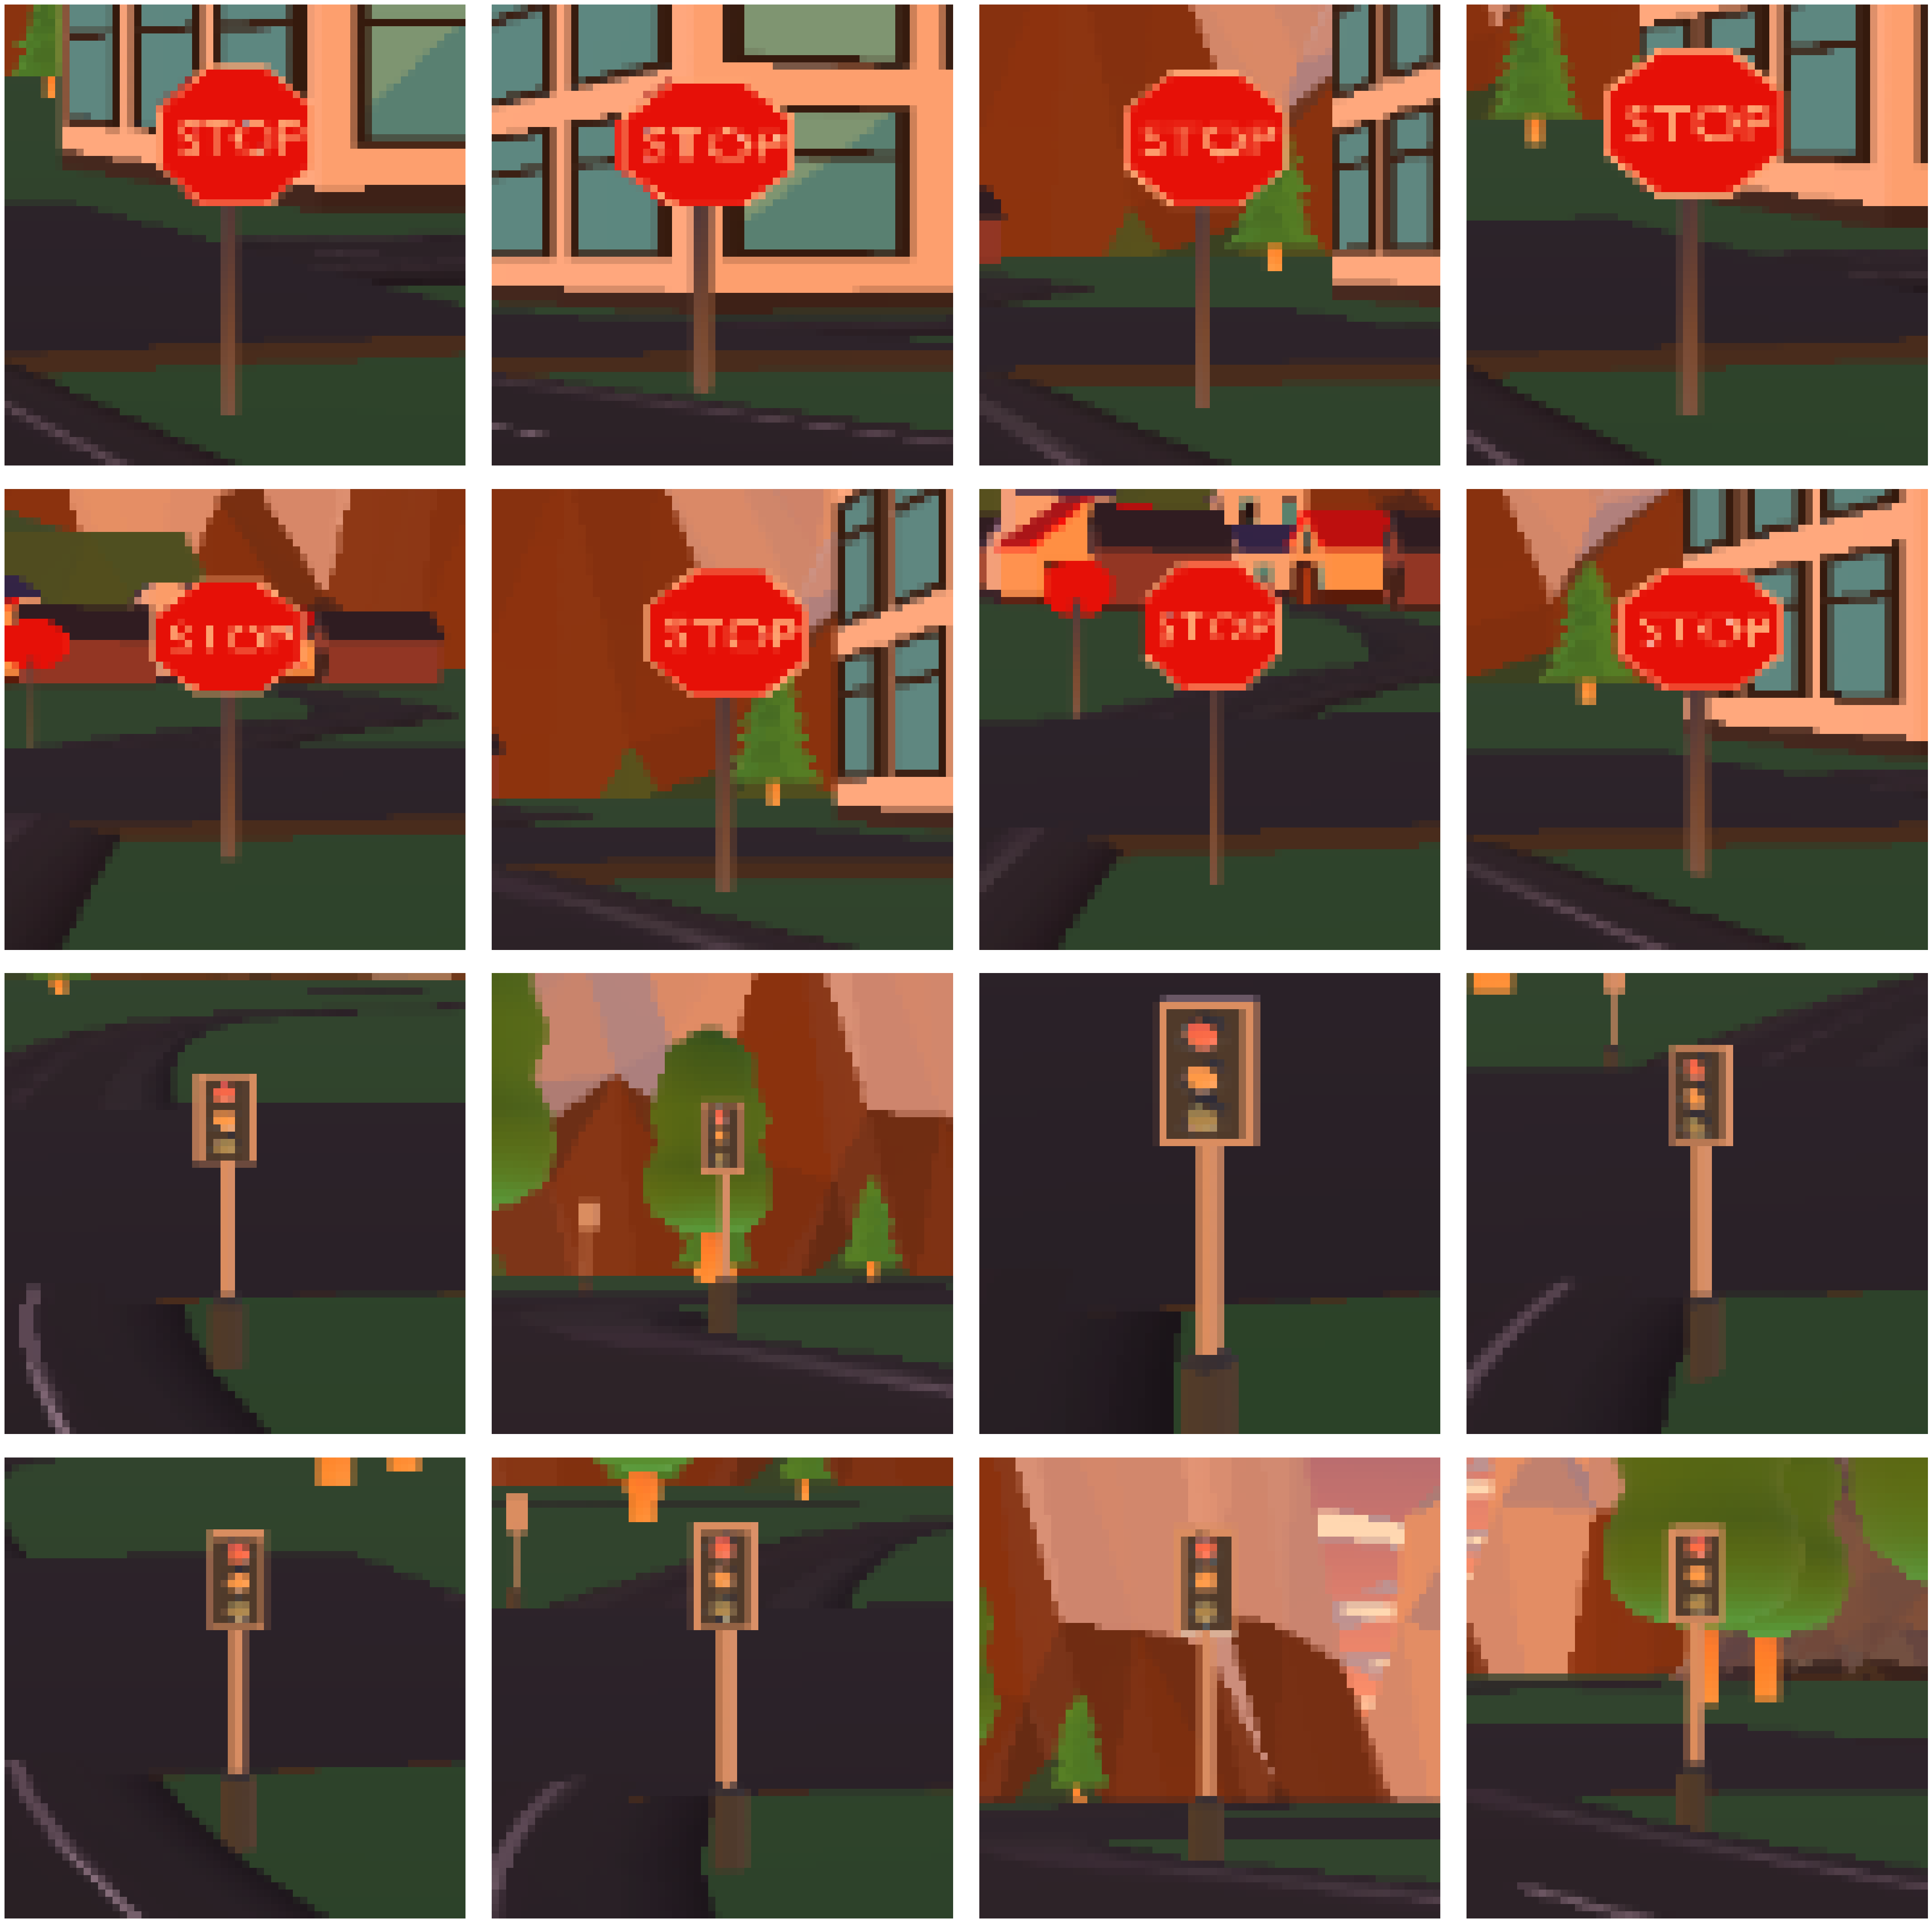

In [3]:
fig, axes = plt.subplots(4, 4, figsize=(55, 55), gridspec_kw={"wspace": 0.05, "hspace": 0.05})

for ax, img in zip(axes.flat, stop_signs_training[:8] + traffic_lights_training[:8]):
    ax.imshow(cv2.cvtColor(img.image, cv2.COLOR_BGR2RGB)); ax.axis("off")
    
plt.show()

# 2. Classification Problem
### This classifier will learn to tell the difference between a stop sign and a traffic light. Both of them appear in the same environment and both have bright colours, both including red, which will be an interesting case to investigate since they mainly differ in physical shape.

# 3. Source Data
### The images are from a Godot game engine environment, and have been captured through scripting a camera to locate itself randomly within a certain volume in front of the object and saving its view as an image. The purpose of this environment for this assignment is to try out how a classic ML classifier would perform for my project, which will be a self driving car in the same environment through actions based on a computer vision pipeline. The images were captured at a higher resolution but cropped into a smaller size to realistically represent how the object would appear in the images of a real video feed.



# 4. Create HOG and feature vectors
### The HOG descriptors parameters are pretty standard, each cell is 8x8 pixels, the blockSize is 16x16 which means 4 cells per block and the winSize is 64x64.


In [4]:
hog = cv2.HOGDescriptor(
    _winSize=(64, 64),
    _blockSize=(16, 16),
    _blockStride=(8, 8),
    _cellSize=(8, 8),
    _nbins=9
)

def features(image):
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    return hog.compute(gray_image).ravel()

In [5]:
feature_vector_train = np.array([features(sample.image) for sample in stop_signs_training] +
                   [features(sample.image) for sample in traffic_lights_training])
labels_train = np.array([0] * len(stop_signs_training) + [1] * len(traffic_lights_training))

feature_vector_test = np.array([features(s.image) for s in stop_signs_testing] +
                  [features(s.image) for s in traffic_lights_testing])
labels_test = np.array([0] * len(stop_signs_testing) + [1] * len(traffic_lights_testing))

        

# 5. Training classifiers SVM and k-NN

In [6]:
#SVM
svm_clf = svm.SVC(kernel='linear').fit(feature_vector_train, labels_train)

#k-NN
knn_clf = KNeighborsClassifier(n_neighbors=3).fit(feature_vector_train, labels_train)

# 6. Testing classifiers + Results

In [7]:
test_samples = stop_signs_testing + traffic_lights_testing

#SVM
svm_score = svm_clf.score(feature_vector_test, labels_test)
svm_prediction = svm_clf.predict(feature_vector_test)

svm_wrong = []
for sample, true, prediction in zip(test_samples, labels_test, svm_prediction):
    if true != prediction:
        svm_wrong.append(sample)
print("SVM score: " + str(svm_score))

#k-NN
knn_score = knn_clf.score(feature_vector_test, labels_test)
knn_prediction = knn_clf.predict(feature_vector_test)

knn_wrong = []
for sample, true, prediction in zip(test_samples, labels_test, knn_prediction):
    if true != prediction:
        knn_wrong.append(sample)
print("k-NN score: " + str(knn_score))

SVM score: 0.9
k-NN score: 0.925


## SVM Confusion Matrix

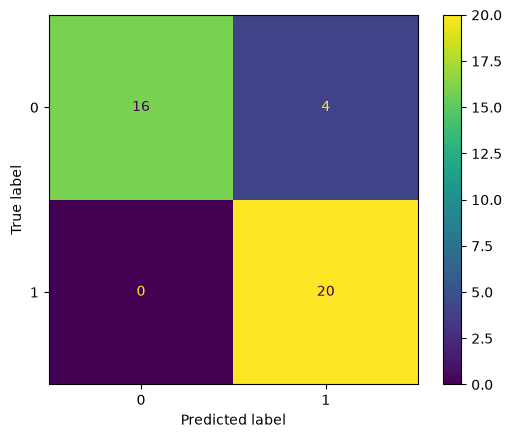

In [8]:
ConfusionMatrixDisplay.from_predictions(labels_test, svm_prediction)

## k-NN Confusion Matrix

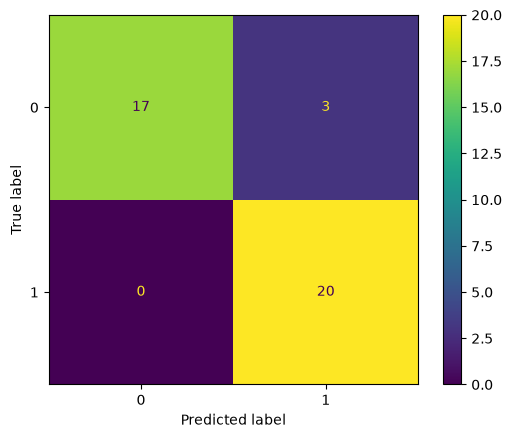

In [9]:
ConfusionMatrixDisplay.from_predictions(labels_test, knn_prediction)

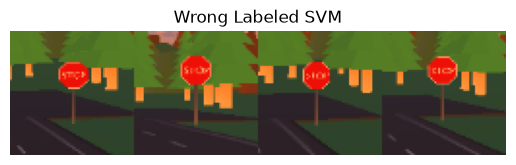

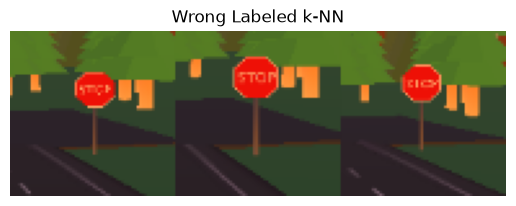

In [10]:
for wrong_sample in svm_wrong:
    wrong_sample.image = cv2.cvtColor(wrong_sample.image, cv2.COLOR_BGR2RGB)

#this may look unnecesary but due to double bgr->rgb flipping this knn image would be flipped back to bgr again if it were'nt for this,
#because of images in both lists being the same instance
knn_wrong[1].image = cv2.cvtColor(knn_wrong[1].image, cv2.COLOR_BGR2RGB)


svm_wrong_stack = np.hstack((svm_wrong[0].image, svm_wrong[1].image, svm_wrong[2].image, svm_wrong[3].image))
knn_wrong_stack = np.hstack((knn_wrong[0].image, knn_wrong[1].image, knn_wrong[2].image))

plt.imshow(svm_wrong_stack)
plt.title("Wrong Labeled SVM")
plt.axis('off')
plt.show()

plt.imshow(knn_wrong_stack)
plt.title("Wrong Labeled k-NN")
plt.axis('off')
plt.show()

# 7. Reflection
### As we can see in the results the k-NN classifier had slightly better accuracy than SVM (3 wrong vs 4 wrong), with k-NN having 92.5% accuracy and SVM 90.0%. The conclusion from that is that they performed the same, the one image difference is probably noise and could shift between datasets. As of my understanding the cost of training the SVM classifier grows along with a larger dataset, but prediction is cheap and constant which makes it suitable for real time detection in a video feed as an example. k-NN on the other hand technically has no training stage, it just remembers the training data as is and use those samples as neighbors for the nearest neighbor operation in the test, which makes training cheap and super fast, but prediction gets slower and more expensive as the training dataset grows since it has to calculate more distances for each test.

### Another interesting observation is that all the falsely labeled images were all the same stop sign in the exact same location, with similar viewing angles for both classifiers. I'm not sure why this particular stop sign caused problems from this angle since it never labeled a traffic light as a stop sign in a similar angle or background, so it doesn't seem like there was an overlapping mixup. The displayed images above were all the falsely labeled samples.

### I think the amount of images is the biggest problem here since I only have 20 for training and 20 for testing for each class, 1000 training and 1000 testing images per class would have been better and I should also have in general used similar but slightly different objects per class so they're not exact duplicates. For my project though I should only train with more images from different angles since that would only feature this exact stop sign and traffic light.